In [71]:
# ADS-505 Team 14
# Predicting Data Center Energy Efficiency Using Machine Learning

In [ ]:
%pip install seaborn

In [ ]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

In [ ]:
DATA_PATH = "green_ai_datacenter.csv"

df = pd.read_csv(DATA_PATH)

df.head()

In [75]:
print(f"Dataset shape: {df.shape}")

df.info()

Dataset shape: (10000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   server_type              10000 non-null  str    
 1   cooling_type             10000 non-null  str    
 2   datacenter_region        6010 non-null   str    
 3   time_of_day              10000 non-null  str    
 4   workload_intensity       10000 non-null  float64
 5   cpu_utilization          10000 non-null  float64
 6   memory_utilization       10000 non-null  float64
 7   network_throughput_gbps  10000 non-null  float64
 8   inlet_temperature_c      10000 non-null  float64
 9   cooling_efficiency       10000 non-null  float64
 10  power_consumption_kw     10000 non-null  float64
 11  carbon_emission_kg       10000 non-null  float64
 12  compute_cost_usd         10000 non-null  float64
 13  pue                      10000 non-null  float64
 14  energy_

In [76]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
server_type,10000,4,Compute,4058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cooling_type,10000,3,Air,4936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
datacenter_region,6010,3,EU,3056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_of_day,10000,3,Peak,4036,NaN,NaN,NaN,NaN,NaN,NaN,NaN
workload_intensity,10000.000,NaN,NaN,NaN,0.547,0.260,0.100,0.320,0.544,0.775,1.000
cpu_utilization,10000.000,NaN,NaN,NaN,46.335,19.409,0.129,30.253,46.398,62.692,91.754
memory_utilization,10000.000,NaN,NaN,NaN,65.723,15.756,5.000,54.995,65.943,76.746,98.000
network_throughput_gbps,10000.000,NaN,NaN,NaN,15.470,7.450,1.756,10.249,14.117,19.340,60.748
inlet_temperature_c,10000.000,NaN,NaN,NaN,22.034,3.917,15.000,19.340,21.910,24.490,37.992
cooling_efficiency,10000.000,NaN,NaN,NaN,0.861,0.096,0.517,0.796,0.870,0.936,1.000


In [77]:
df.columns.tolist()

['server_type',
 'cooling_type',
 'datacenter_region',
 'time_of_day',
 'workload_intensity',
 'cpu_utilization',
 'memory_utilization',
 'network_throughput_gbps',
 'inlet_temperature_c',
 'cooling_efficiency',
 'power_consumption_kw',
 'carbon_emission_kg',
 'compute_cost_usd',
 'pue',
 'energy_efficiency_class']

In [78]:
TARGET = "Energy_Efficiency"

In [79]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['server_type', 'cooling_type', 'datacenter_region', 'time_of_day', 'workload_intensity', 'cpu_utilization', 'memory_utilization', 'network_throughput_gbps', 'inlet_temperature_c', 'cooling_efficiency', 'power_consumption_kw', 'carbon_emission_kg', 'compute_cost_usd', 'pue', 'energy_efficiency_class']


In [80]:
missing_values = (
    df.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_values[missing_values > 0]

datacenter_region    3990
dtype: int64

In [81]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [82]:
df.nunique().sort_values()

cooling_type                  3
datacenter_region             3
time_of_day                   3
energy_efficiency_class       3
server_type                   4
cooling_efficiency          432
workload_intensity          901
pue                         979
inlet_temperature_c        6815
compute_cost_usd           7451
network_throughput_gbps    8169
memory_utilization         8903
carbon_emission_kg         9041
cpu_utilization            9326
power_consumption_kw       9403
dtype: int64

In [83]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if TARGET in numeric_features:
    numeric_features.remove(TARGET)

if TARGET in categorical_features:
    categorical_features.remove(TARGET)

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['workload_intensity', 'cpu_utilization', 'memory_utilization', 'network_throughput_gbps', 'inlet_temperature_c', 'cooling_efficiency', 'power_consumption_kw', 'carbon_emission_kg', 'compute_cost_usd', 'pue']

Categorical features:
['server_type', 'cooling_type', 'datacenter_region', 'time_of_day', 'energy_efficiency_class']


In [84]:
df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
workload_intensity,10000.000,0.547,0.260,0.100,0.320,0.544,0.775,1.000
cpu_utilization,10000.000,46.335,19.409,0.129,30.253,46.398,62.692,91.754
memory_utilization,10000.000,65.723,15.756,5.000,54.995,65.943,76.746,98.000
network_throughput_gbps,10000.000,15.470,7.450,1.756,10.249,14.117,19.340,60.748
inlet_temperature_c,10000.000,22.034,3.917,15.000,19.340,21.910,24.490,37.992
cooling_efficiency,10000.000,0.861,0.096,0.517,0.796,0.870,0.936,1.000
power_consumption_kw,10000.000,82.092,26.630,28.169,64.186,77.900,95.799,233.630
carbon_emission_kg,10000.000,33.123,15.397,5.069,21.867,30.029,41.383,136.022
compute_cost_usd,10000.000,10.131,4.975,1.084,6.530,9.329,12.916,42.053
pue,10000.000,1.481,0.203,1.050,1.350,1.469,1.595,2.596


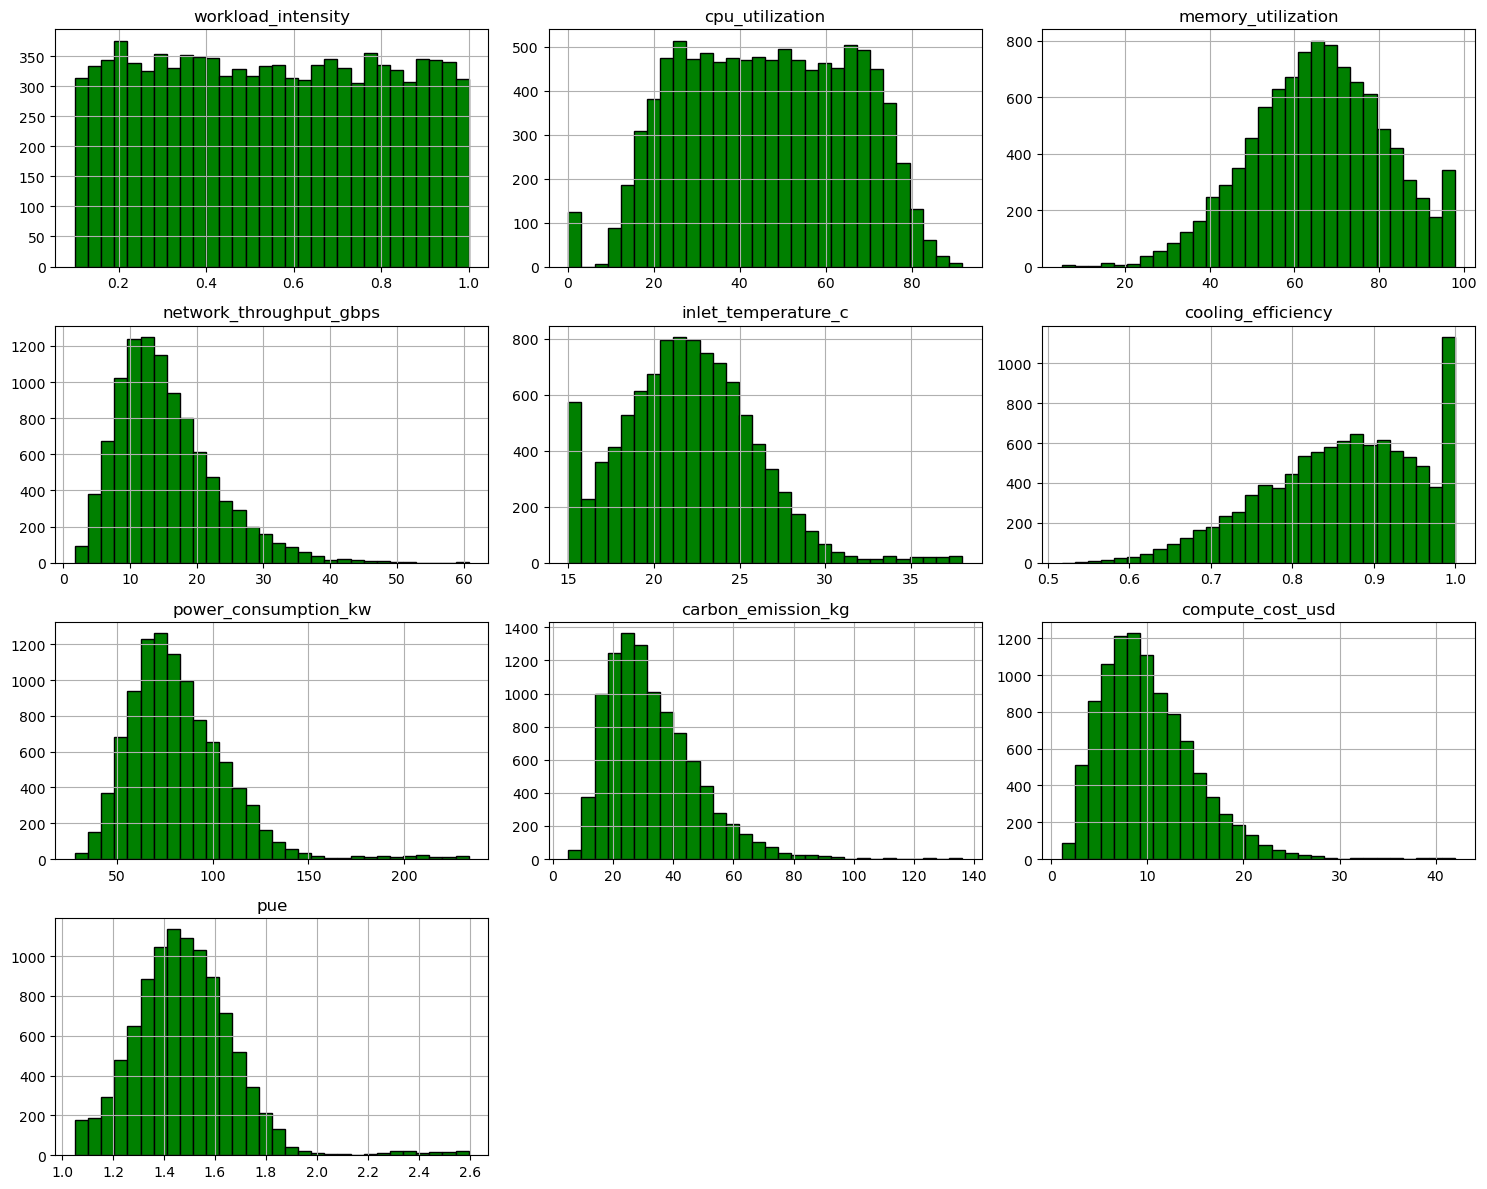

In [85]:
df[numeric_features].hist(
    figsize=(15, 12),
    bins=30,
    color='green',
    edgecolor='black'
)

plt.tight_layout()
plt.show()

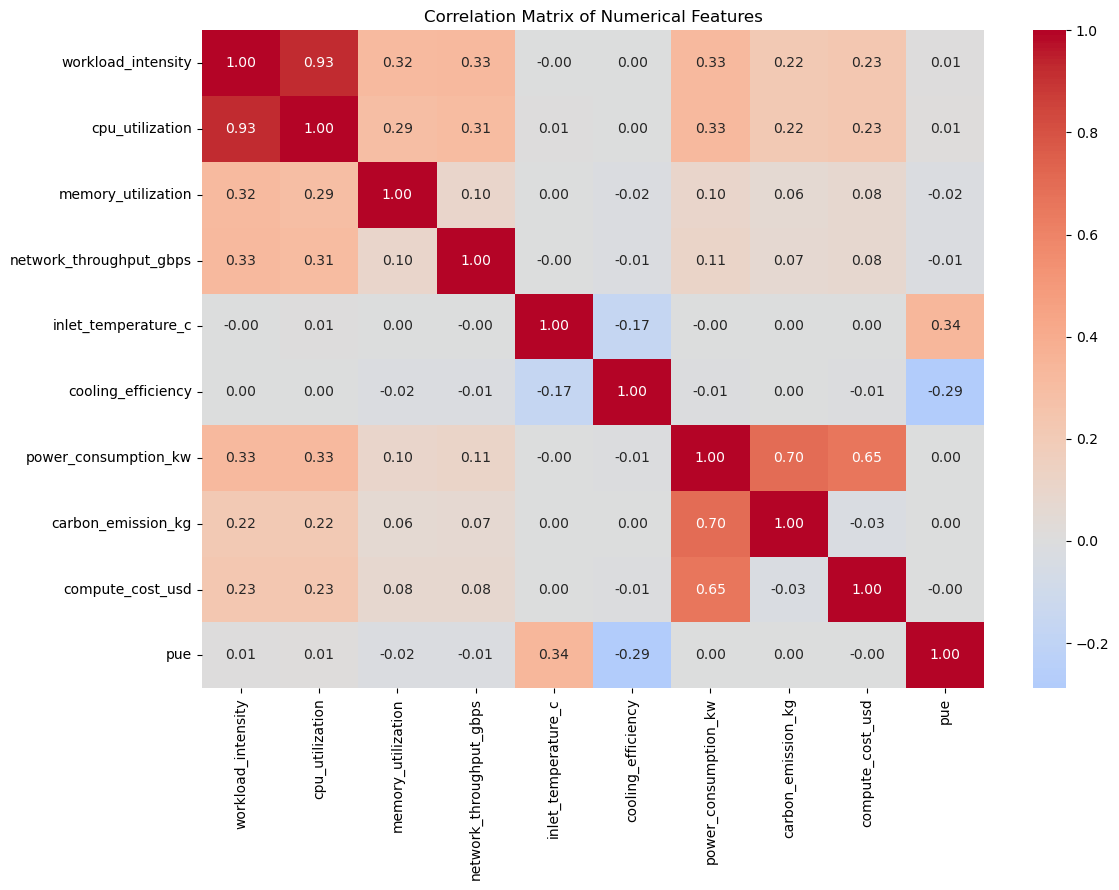

In [86]:
correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

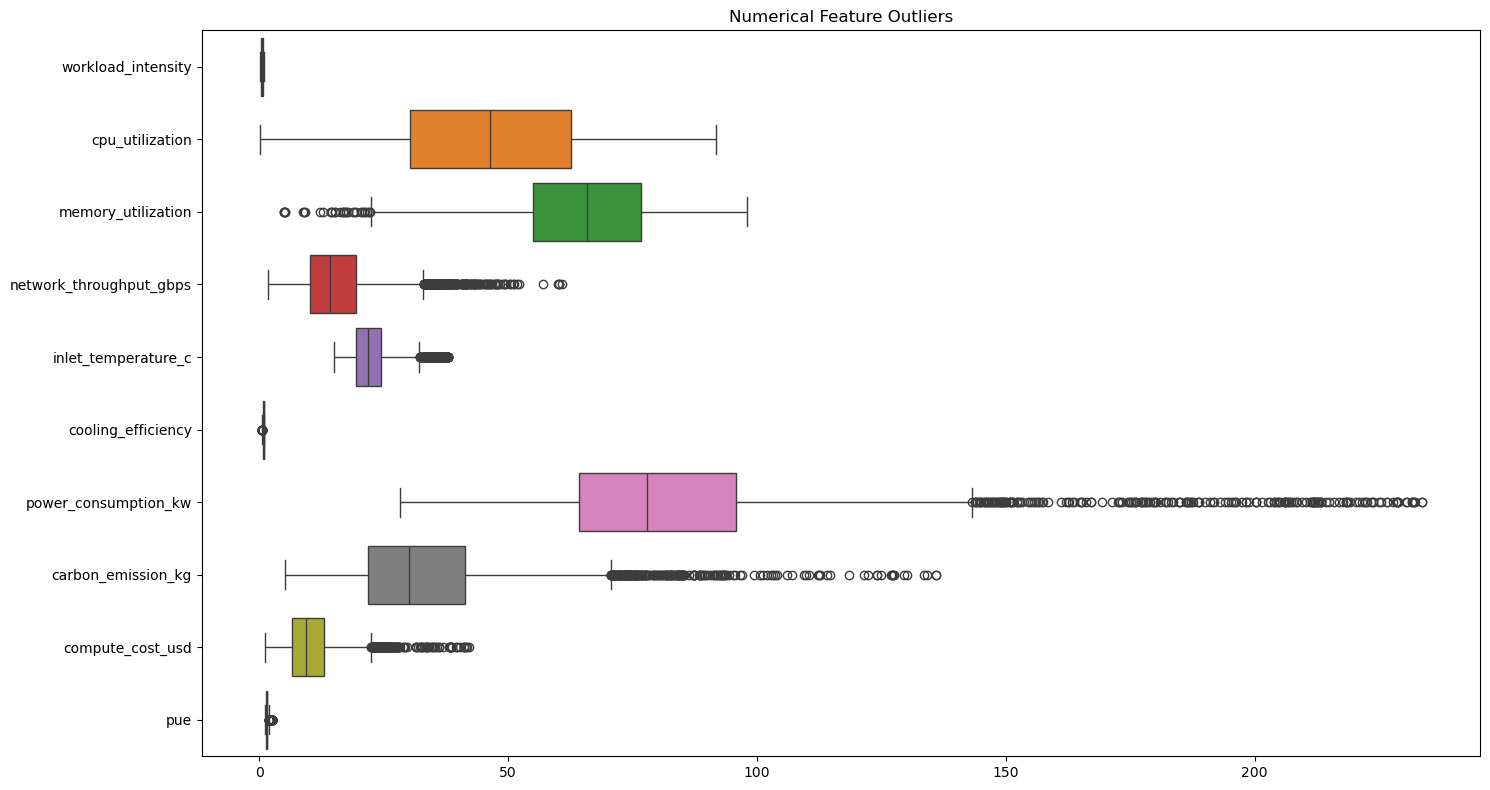

In [87]:
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=df[numeric_features],
    orient="h"
)

plt.title("Numerical Feature Outliers")
plt.tight_layout()
plt.show()

In [88]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)

IQR = Q3 - Q1

outlier_counts = (
    ((df[numeric_features] < (Q1 - 1.5 * IQR)) |
     (df[numeric_features] > (Q3 + 1.5 * IQR)))
    .sum()
    .sort_values(ascending=False)
)

outlier_counts

network_throughput_gbps    278
carbon_emission_kg         226
power_consumption_kw       209
compute_cost_usd           182
pue                        150
inlet_temperature_c        145
cooling_efficiency          35
memory_utilization          32
workload_intensity           0
cpu_utilization              0
dtype: int64

In [89]:
print(df.columns.tolist())

['server_type', 'cooling_type', 'datacenter_region', 'time_of_day', 'workload_intensity', 'cpu_utilization', 'memory_utilization', 'network_throughput_gbps', 'inlet_temperature_c', 'cooling_efficiency', 'power_consumption_kw', 'carbon_emission_kg', 'compute_cost_usd', 'pue', 'energy_efficiency_class']


In [90]:
TARGET = "EnergyEfficiency"

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [ ]:
print("X_train columns:", X_train.columns.tolist())
print("Target:", TARGET)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

print("Baseline accuracy:", round(baseline_accuracy, 4))

In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

In [ ]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

In [ ]:
forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

In [104]:
models = {
    "Baseline": baseline_predictions,
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions,
    "Gradient Boosting": gradient_predictions
}

results = []

for model_name, predictions in models.items():
    results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_test,
                predictions
            ),
            "Precision": precision_score(
                y_test,
                predictions,
                average="weighted",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                predictions,
                average="weighted",
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                predictions,
                average="weighted",
                zero_division=0
            )
        }
    )

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1
4,Gradient Boosting,0.983,0.983,0.983,0.983
2,Decision Tree,0.980,0.980,0.980,0.980
3,Random Forest,0.967,0.967,0.967,0.967
1,Logistic Regression,0.939,0.940,0.939,0.939
0,Baseline,0.340,0.116,0.340,0.173


In [103]:
print("Logistic Regression")
print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

print("Random Forest")
print(
    classification_report(
        y_test,
        forest_predictions,
        zero_division=0
    )
)

print("Gradient Boosting")
print(
    classification_report(
        y_test,
        gradient_predictions,
        zero_division=0
    )
)

Logistic Regression
              precision    recall  f1-score   support

        High       0.97      0.97      0.97       680
         Low       0.96      0.91      0.93       660
      Medium       0.89      0.94      0.91       660

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000

Random Forest
              precision    recall  f1-score   support

        High       0.99      0.96      0.97       680
         Low       0.98      0.97      0.97       660
      Medium       0.93      0.97      0.95       660

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000

Gradient Boosting
              precision    recall  f1-score   support

        High       0.99      0.98      0.99       680
         Low       0.99      0.97      0.98       660
      Medium       0.96

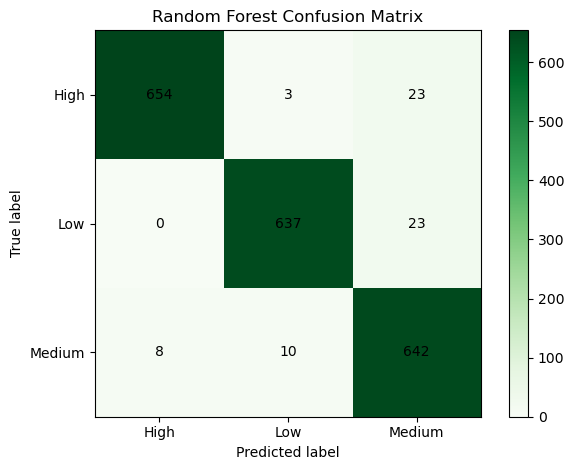

In [102]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions,
    cmap="Greens",
    text_kw={"color": "black"}
)

plt.title("Random Forest Confusion Matrix", color="black")
plt.tight_layout()
plt.show()

In [101]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [100]:
param_grid = {
    "classifier__n_estimators": [
        100,
        200,
        300
    ],
    "classifier__max_depth": [
        None,
        10,
        20
    ],
    "classifier__min_samples_split": [
        2,
        5,
        10
    ]
}

In [99]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : 

In [98]:
print("Best parameters:")
print(grid_search.best_params_)

print(
    f"\nBest cross-validation F1: "
    f"{grid_search.best_score_:.3f}"
)

Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best cross-validation F1: 0.959


In [94]:
best_model = grid_search.best_estimator_

final_predictions = best_model.predict(X_test)

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions,
    average="weighted",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_predictions,
    average="weighted",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_predictions,
    average="weighted",
    zero_division=0
)

final_results = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ],
        "Score": [
            final_accuracy,
            final_precision,
            final_recall,
            final_f1
        ]
    }
)

final_results

,Metric,Score
0,Accuracy,0.968
1,Precision,0.969
2,Recall,0.968
3,F1,0.968


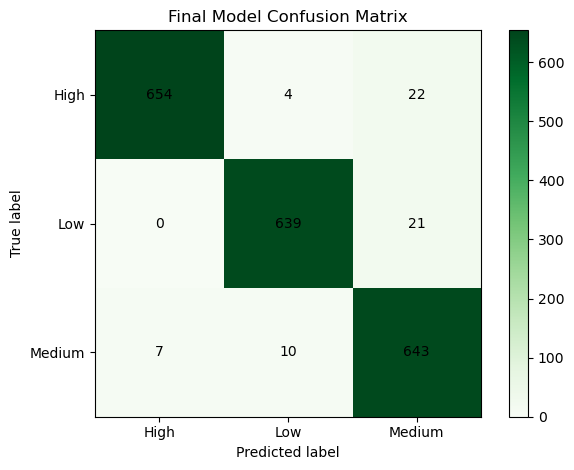

In [95]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    cmap="Greens",
    text_kw={"color": "black"}
)

plt.title("Final Model Confusion Matrix", color="black")
plt.tight_layout()
plt.show()

In [96]:
classifier = best_model.named_steps["classifier"]
processor = best_model.named_steps["preprocessor"]

feature_names = processor.get_feature_names_out()

importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    }
)

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
9,num__pue,0.623
5,num__cooling_efficiency,0.123
4,num__inlet_temperature_c,0.048
3,num__network_throughput_gbps,0.022
2,num__memory_utilization,0.022
0,num__workload_intensity,0.022
1,num__cpu_utilization,0.022
8,num__compute_cost_usd,0.021
7,num__carbon_emission_kg,0.021
6,num__power_consumption_kw,0.021


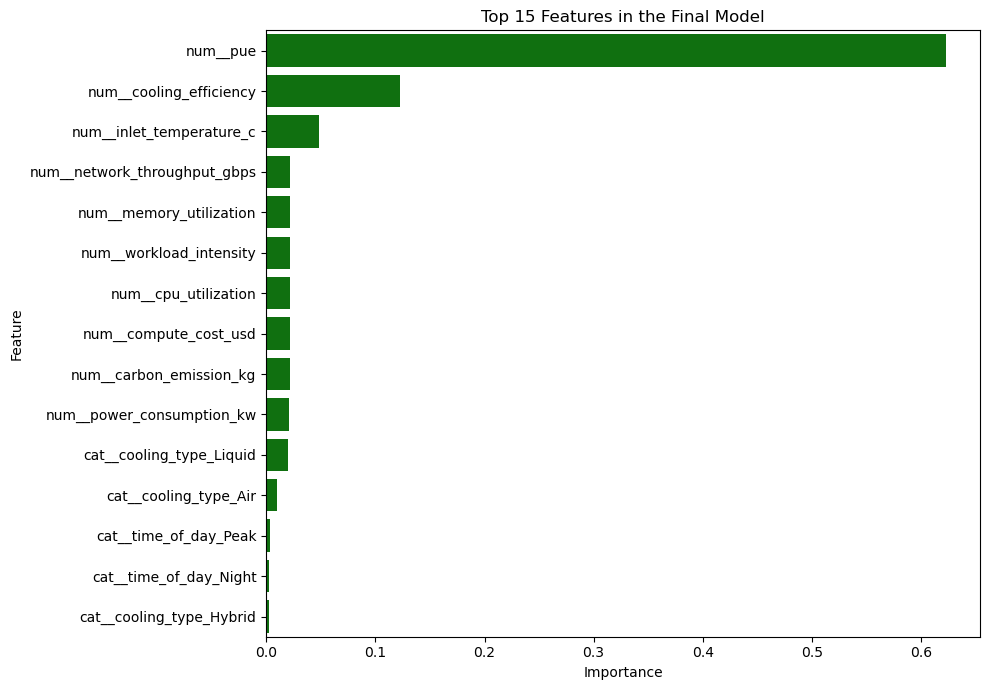

In [97]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="green"
)

plt.title("Top 15 Features in the Final Model", color="black")
plt.xlabel("Importance", color="black")
plt.ylabel("Feature", color="black")
plt.tick_params(axis="both", colors="black")

plt.tight_layout()
plt.show()

In [ ]:
## Discussion and Conclusion

This project evaluated several machine learning classification methods
for predicting data center energy efficiency as low, medium, or high.
The analysis began with exploratory data analysis and preprocessing to
identify missing values, outliers, class imbalance, and correlations
among predictors.

The models demonstrated different levels of predictive performance.
The final model was selected by comparing it with the baseline and
evaluating multiple classification metrics rather than relying on
accuracy alone.

The most important predictors identified by the final model provide
additional insight into which telemetry characteristics are associated
with differences in predicted energy efficiency. These findings may
support future monitoring and efficiency-tracking applications.

However, the results should be interpreted cautiously because the
dataset is synthetic and may not fully represent real-world data center
operations. Before deployment, the model should be tested against
real telemetry data and monitored for changes in performance over time.

Future work could include cost-sensitive classification, model
interpretability methods such as SHAP, time-based validation, model
drift monitoring, and testing additional machine learning algorithms.